# 1D Lennard-Jones MD for argon, in JAX

NVE molecular dynamics of identical, uncharged particles on a periodic line, written with `jax` (autodiff forces, `jit`, `lax.scan`). The physics lives in `lj.py`; this notebook runs it and checks the results against what we expect.

Units: length in Å, energy in K (energy / k_B), mass in u, time in the unit that follows from these.

Each experiment has a short **Expectation**, a calculation cell, a plot cell, and a short **Expectation met?** note.

In [34]:
import subprocess
import sys
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import lj

P = lj.ARGON
SIGMA, EPS, MASS = P["sigma"], P["epsilon"], P["mass"]
R_MIN = 2 ** (1 / 6) * SIGMA  # analytical minimum U: sixth root of 2 times sigma (about 3.82 A)
DT = 0.002  # time step
BOX_PAIR = 20 * SIGMA  # large box: a single pair does not feel its own image

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"sigma = {SIGMA} A, epsilon/k_B = {EPS} K, r_min = 2^(1/6) sigma = {R_MIN:.4f} A")

sigma = 3.405 A, epsilon/k_B = 119.8 K, r_min = 2^(1/6) sigma = 3.8220 A


# Sanity checks

## Unit tests

**Expectation:** every test in `test_lj.py` passes. If this cell fails, do not trust anything below.

In [35]:
proc = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "test_lj.py"],
    capture_output=True, text=True, cwd=Path(lj.__file__).parent,
)
print(proc.stdout.strip().splitlines()[-1])
assert proc.returncode == 0, proc.stdout

16 passed in 4.79s


## Autodiff force vs analytic force

**Expectation:** the force from `jax.grad` of the energy equals the hand-derived analytic force up to rounding. We check the **absolute** difference for a pair at 0.9 σ to 3 σ and require it to stay below 1e-9 K/Å.

In [36]:
# calculation
r_grid = jnp.linspace(0.9 * SIGMA, 3.0 * SIGMA, 400)
f_analytic = lj.lj_force_analytic(r_grid, P)
# force on particle 1 of a pair placed at x = 0 and x = r
f_autodiff = jax.vmap(lambda r: lj.forces(jnp.array([0.0, r]), BOX_PAIR, P)[1])(r_grid)
abs_diff = jnp.abs(f_autodiff - f_analytic)  # K / Angstrom
u_values = lj.pair_energy(r_grid, P)  # potential energy of the pair, K

TOLERANCE = 1e-9
grad_check = {
    "max_abs_diff": float(abs_diff.max()),
    "r_at_max": float(r_grid[abs_diff.argmax()]),
    "max_abs_force": float(jnp.abs(f_analytic).max()),
}

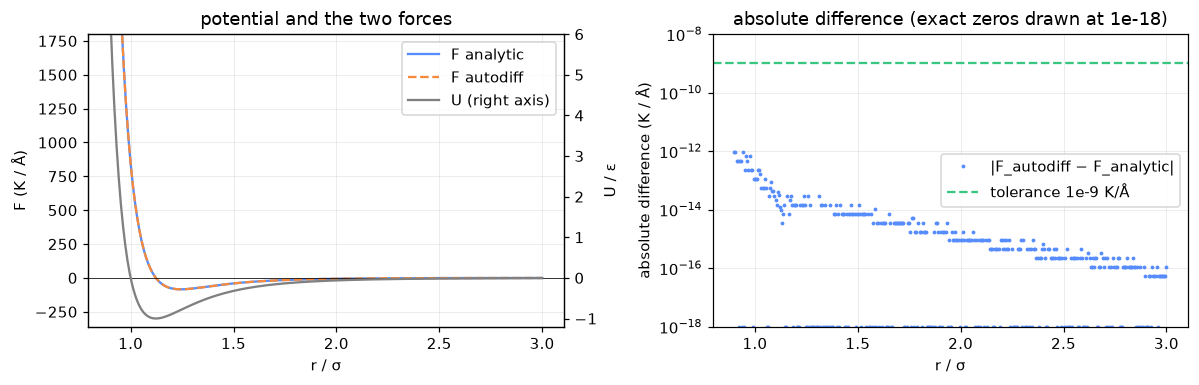

largest absolute difference: 9.1e-13 K/A at r = 0.90 sigma (largest force in range: 4.9e+03 K/A)


In [37]:
# plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(r_grid / SIGMA, f_analytic, label="F analytic")
ax1.plot(r_grid / SIGMA, f_autodiff, "--", label="F autodiff")
ax1.axhline(0, color="k", lw=0.5)
ax1.set(xlabel="r / σ", ylabel="F (K / Å)", ylim=(-360, 1800), title="potential and the two forces")
# potential on a second axis; both ranges have the ratio 1 : 5, so the zero lines coincide
ax1u = ax1.twinx()
ax1u.plot(r_grid / SIGMA, u_values / EPS, color="grey", label="U (right axis)")
ax1u.set(ylabel="U / ε", ylim=(-1.2, 6.0))
ax1u.grid(False)
handles = ax1.get_legend_handles_labels()[0] + ax1u.get_legend_handles_labels()[0]
ax1.legend(handles=handles, loc="upper right")
ax2.semilogy(r_grid / SIGMA, np.maximum(abs_diff, 1e-18), ".", ms=3, label="|F_autodiff − F_analytic|")
ax2.axhline(TOLERANCE, color="C3", ls="--", label="tolerance 1e-9 K/Å")
ax2.set(xlabel="r / σ", ylabel="absolute difference (K / Å)", ylim=(1e-18, 1e-8),
        title="absolute difference (exact zeros drawn at 1e-18)")
ax2.legend()
fig.tight_layout()
plt.show()
print(f"largest absolute difference: {grad_check['max_abs_diff']:.1e} K/A at r = {grad_check['r_at_max'] / SIGMA:.2f} sigma "
      f"(largest force in range: {grad_check['max_abs_force']:.1e} K/A)")

> **Expectation met?** Yes. The largest difference is 9e-13 K/Å, at 0.9 σ where the force is also largest (about 5e3 K/Å). That is double-precision rounding, so autodiff gives the exact derivative of the implemented energy.

# Two particles

Two particles in a periodic box of 20 σ, released **at rest**. The energy is then E = U(r₀), which is negative, so the pair is bound and oscillates between two turning points. The minimum of the potential is at the sixth root of two times σ:

$$r_{min} = 2^{1/6}\,\sigma \approx 3.82\ \text{Å}, \qquad U(r_{min}) = -\epsilon .$$

## Equilibrium distance

**Expectation:** In harmonic approximation the pair oscillates around r_min, so its time-averaged separation equals r_min. (At constant energy it never settles into the minimum, it oscillates around it.)

We run one large oscillation (released at 1.3 σ) and a sweep over offsets a, with the pair released at r_min (1 + a).

In [38]:
# calculation: one large oscillation and an offset sweep
R0 = 1.3 * SIGMA
N_STEPS = 40_000
_, traj = lj.run(lj.init_state(jnp.array([0.0, R0]), BOX_PAIR, P), BOX_PAIR, DT, N_STEPS, P)
sep = traj.pos[:, 1] - traj.pos[:, 0]
t = DT * jnp.arange(1, N_STEPS + 1)
pair = {
    "E0": float(traj.total[0]),
    "r_lo": float(sep.min()), "r_hi": float(sep.max()),   # turning points
    "r_mean": float(sep.mean()),
}

# offset sweep: released at rest at R_MIN * (1 + a); 8000 steps are about 14 periods
offsets = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
sweep = {"offset": offsets, "period": [], "mean_shift": []}
for a in offsets:
    _, tr = lj.run(lj.init_state(jnp.array([0.0, R_MIN * (1 + a)]), BOX_PAIR, P), BOX_PAIR, DT, 8000, P)
    s = tr.pos[:, 1] - tr.pos[:, 0]
    s0 = s - s.mean()
    up = jnp.where((s0[:-1] < 0) & (s0[1:] >= 0))[0]            # upward zero crossings
    t_cross = (up + (-s0[up] / (s0[up + 1] - s0[up]))) * DT       # linear interpolation
    sweep["period"].append(float(jnp.mean(jnp.diff(t_cross))))
    whole_periods = s[int(up[0]):int(up[-1])]                     # average over whole periods only
    sweep["mean_shift"].append(float((whole_periods.mean() - R_MIN) / R_MIN))

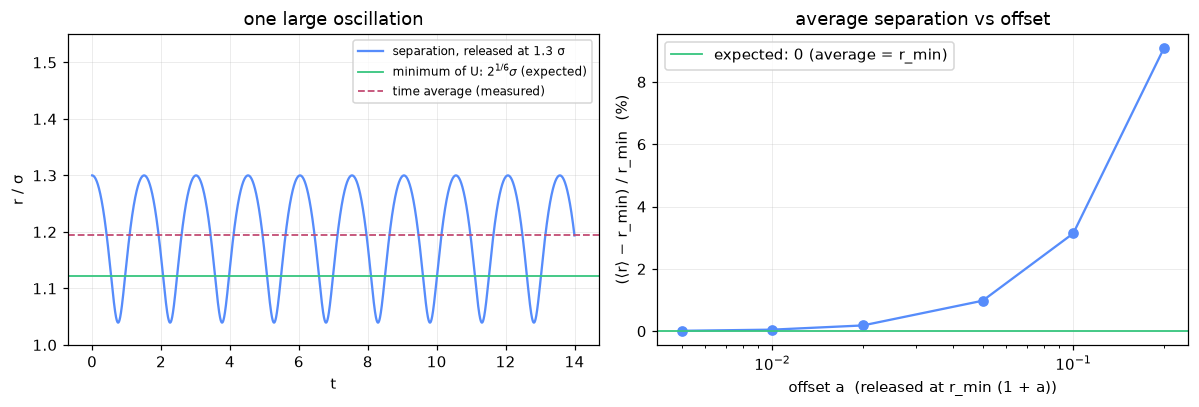

r_min = 1.1225 sigma;  large oscillation: <r> = 1.1945 sigma, turning points 1.039 and 1.300 sigma
mean shift (%) for a = {0.005: 0.013, 0.01: 0.049, 0.02: 0.184, 0.05: 0.978, 0.1: 3.139, 0.2: 9.079}


In [39]:
# plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
m = t < 14
ax1.plot(t[m], sep[m] / SIGMA, label=f"separation, released at {R0 / SIGMA:.1f} σ")
ax1.axhline(R_MIN / SIGMA, color="C3", lw=1.2, label=r"minimum of U: $2^{1/6}\sigma$ (expected)")
ax1.axhline(pair["r_mean"] / SIGMA, color="C2", ls="--", lw=1.2, label="time average (measured)")
ax1.set(xlabel="t", ylabel="r / σ", ylim=(1.0, 1.55), title="one large oscillation")
ax1.legend(loc="upper right", fontsize=8)
ax2.semilogx(sweep["offset"], 100 * np.array(sweep["mean_shift"]), "o-")
ax2.axhline(0, color="C3", lw=1.2, label="expected: 0 (average = r_min)")
ax2.set(xlabel="offset a  (released at r_min (1 + a))", ylabel="(⟨r⟩ − r_min) / r_min  (%)",
        title="average separation vs offset")
ax2.legend()
fig.tight_layout()
plt.show()
print(f"r_min = {R_MIN / SIGMA:.4f} sigma;  large oscillation: <r> = {pair['r_mean'] / SIGMA:.4f} sigma, "
      f"turning points {pair['r_lo'] / SIGMA:.3f} and {pair['r_hi'] / SIGMA:.3f} sigma")
print("mean shift (%) for a =", {float(a): round(100 * s, 3) for a, s in zip(offsets, sweep["mean_shift"])})

> **Expectation met?** Only for small offsets. For the large oscillation the pair moves between 1.04 σ and 1.30 σ, and its time average is 1.194 σ, 6.4 % above r_min = 1.122 σ. In the sweep the shift is below 0.05 % up to a = 1 % and grows roughly as a² (9 % at a = 20 %). The potential is anharmonic: steep on the inside (r⁻¹²), flat on the outside, so the pair spends more time at r > r_min.

## Distribution of the separation

**Expectation:** The pair oscillates between the turning points, being slowest at the turning point, thus spending most time there.

In [40]:
# calculation
hist, edges = np.histogram(np.asarray(sep / SIGMA), bins=40, density=True)
centres = 0.5 * (edges[1:] + edges[:-1])
r_lo, r_hi = pair["r_lo"] / SIGMA, pair["r_hi"] / SIGMA
uniform_density = 1.0 / (r_hi - r_lo)  # constant density between the turning points
distribution = {
    "hist": hist, "edges": edges, "centres": centres, "uniform": uniform_density,
    "max_over_uniform": float(hist.max() / uniform_density),
    "min_over_uniform": float(hist.min() / uniform_density),
    "mid_over_uniform": float(hist[len(hist) // 2] / uniform_density),
}

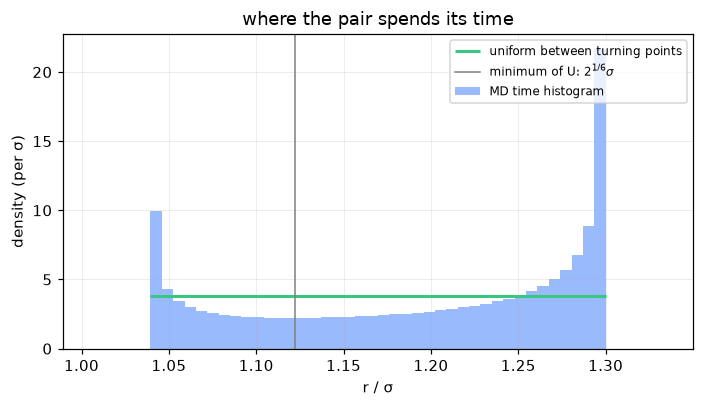

uniform density 3.84; measured: min 0.58x, middle 0.63x, max 5.64x uniform


In [41]:
# plot
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(distribution["centres"], distribution["hist"], width=np.diff(distribution["edges"]),
       alpha=0.6, label="MD time histogram")
ax.hlines(distribution["uniform"], r_lo, r_hi, color="C3", lw=2, label="uniform between turning points")
ax.axvline(R_MIN / SIGMA, color="grey", lw=1, label=r"minimum of U: $2^{1/6}\sigma$")
ax.set(xlabel="r / σ", ylabel="density (per σ)", xlim=(r_lo - 0.05, r_hi + 0.05),
       title="where the pair spends its time")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"uniform density {distribution['uniform']:.2f}; measured: min {distribution['min_over_uniform']:.2f}x, "
      f"middle {distribution['mid_over_uniform']:.2f}x, max {distribution['max_over_uniform']:.2f}x uniform")

> **Expectation met?** Yes, also anharmonic effects are observable for the bir r utrning point

## Oscillation period

**Expectation:** for small offsets the potential is harmonic around r_min, so the period is T₀ = 2π √(μ / U''(r_min)) with the reduced mass μ = m/2. We accept a deviation below 1 %. U''(r_min) comes from applying `jax.grad` twice to `pair_energy`; analytically it is 36 · 2^(2/3) ε/σ² ≈ 57.15 ε/σ². The periods are taken from the offset sweep above.

In [48]:
# calculation
u_second = jax.grad(jax.grad(lj.pair_energy))(R_MIN, P)         # U''(r_min), K / A^2
period_harmonic = float(2 * jnp.pi / jnp.sqrt(u_second / (MASS / 2)))
periods = np.array(sweep["period"])
period_deviation = (periods - period_harmonic) / period_harmonic   # relative
frequency = {
    "u_second_reduced": float(u_second * SIGMA**2 / EPS),
    "u_second_analytic": 36 * 2 ** (2 / 3),
    "period_harmonic": period_harmonic,
    "deviation": period_deviation,
}

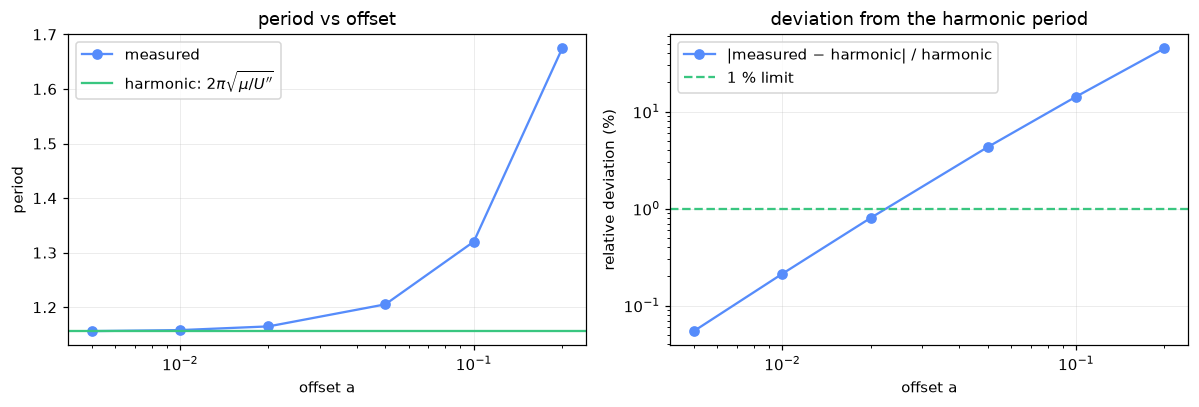

U''(r_min) = 57.146 eps/sigma^2 (analytic 57.146); harmonic period = 1.1556
deviation (%) for a = {0.005: 0.054, 0.01: 0.212, 0.02: 0.801, 0.05: 4.299, 0.1: 14.243, 0.2: 44.907}


In [49]:
# plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.semilogx(sweep["offset"], periods, "o-", label="measured")
ax1.axhline(frequency["period_harmonic"], color="C3", label=r"harmonic: $2\pi\sqrt{\mu/U''}$")
ax1.set(xlabel="offset a", ylabel="period", title="period vs offset")
ax1.legend()
ax2.loglog(sweep["offset"], 100 * np.abs(frequency["deviation"]), "o-", label="|measured − harmonic| / harmonic")
ax2.axhline(1.0, color="C3", ls="--", label="1 % limit")
ax2.set(xlabel="offset a", ylabel="relative deviation (%)", title="deviation from the harmonic period")
ax2.legend()
fig.tight_layout()
plt.show()
print(f"U''(r_min) = {frequency['u_second_reduced']:.3f} eps/sigma^2 (analytic {frequency['u_second_analytic']:.3f}); "
      f"harmonic period = {frequency['period_harmonic']:.4f}")
print("deviation (%) for a =", {float(a): round(float(100 * d), 3) for a, d in zip(sweep["offset"], frequency["deviation"])})

> **Expectation met?** Yes, for small offsets. U'' from autodiff (57.146 ε/σ²) equals the analytic value, and the measured period deviates from the harmonic one by 0.05 % at a = 0.5 %, 0.2 % at 1 % and 0.8 % at 2 %. Beyond about 2 % the deviation exceeds the 1 % limit (4 % at 5 %, 45 % at 20 %), and the period is always longer than the harmonic one: larger oscillations reach the soft outer side of the well, where the restoring force is weaker and the harmonic approximation fails.

## Energy conservation

**Expectation:** velocity Verlet is a second-order method, so the maximum relative energy error over a run scales as dt². On a log-log plot the slope should be 2. The same bound pair is integrated over a fixed total time with different time steps.

In [50]:
# calculation
T_TOTAL = 4.0  # total time, a few oscillation periods
dts = np.array([0.0005, 0.001, 0.002, 0.004, 0.008])
state_drift = lj.init_state(jnp.array([0.0, R0]), BOX_PAIR, P)
drifts = []
for dt in dts:
    _, tr = lj.run(state_drift, BOX_PAIR, float(dt), int(round(T_TOTAL / dt)), P)
    drifts.append(float(jnp.max(jnp.abs(tr.total - tr.total[0])) / abs(tr.total[0])))
drifts = np.array(drifts)
drift_slope = float(np.polyfit(np.log(dts), np.log(drifts), 1)[0])

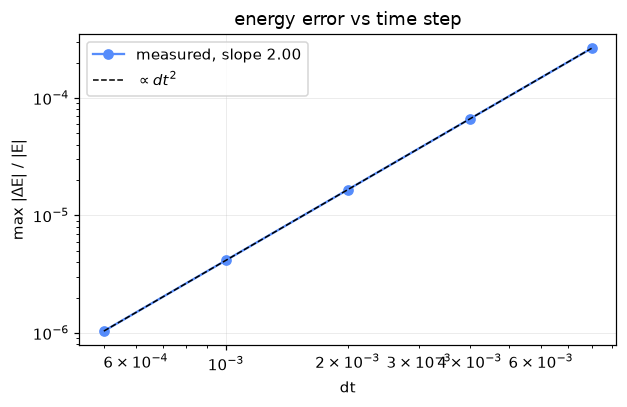

max relative energy error: {0.0005: '1.0e-06', 0.001: '4.1e-06', 0.002: '1.7e-05', 0.004: '6.6e-05', 0.008: '2.7e-04'}


In [51]:
# plot
fig, ax = plt.subplots(figsize=(5.8, 3.8))
ax.loglog(dts, drifts, "o-", label=f"measured, slope {drift_slope:.2f}")
ax.loglog(dts, drifts[0] * (dts / dts[0]) ** 2, "k--", lw=1, label=r"$\propto dt^2$")
ax.set(xlabel="dt", ylabel="max |ΔE| / |E|", title="energy error vs time step")
ax.legend()
fig.tight_layout()
plt.show()
print("max relative energy error:", {float(d): f"{x:.1e}" for d, x in zip(dts, drifts)})

> **Expectation met?** Yes. The error falls from 2.7e-4 at dt = 0.008 to 1.0e-6 at dt = 0.0005, about a factor 4 per halving of dt, and the fitted slope is 2.0. The plot shows only the maximum error, not its time course.

# Chain of N particles

N = 40 particles on a periodic line, started on a lattice with a random displacement and zero velocity. The displacement stores potential energy, so the total energy is fixed at the start and the temperature is **measured** (from the kinetic energy, N − 1 degrees of freedom) over the second half of the run; the first half is discarded as equilibration. Two densities ρ* = Nσ/box: 0.5 (dilute) and 0.9 (dense).

**Expectation:** We expect a clustering around the potential energy minima, thus periodic peaks of density

In [46]:
# calculation
N = 40
N_CHAIN_STEPS = 100_000
HALF = N_CHAIN_STEPS // 2
SMOOTH = 500  # moving-average window (steps) for the temperature plot
chains = {}
for name, rho, jitter in [("dilute", 0.5, 0.3), ("dense", 0.9, 0.1)]:
    box = N * SIGMA / rho
    pos = lj.init_lattice(N, box, jitter, jax.random.PRNGKey(0))
    _, tr = lj.run(lj.init_state(pos, box, P), box, DT, N_CHAIN_STEPS, P)
    temperature_t = 2 * tr.kinetic / (N - 1)                      # K, one value per step
    r, g = lj.g_of_r(jnp.mod(tr.pos[HALF::20], box), box, n_bins=120, r_max=4 * SIGMA)
    chains[name] = {
        "rho": rho, "box": box, "r": r, "g": g, "temperature_t": temperature_t,
        "T": float(temperature_t[HALF:].mean()),
        "temperature_smooth": np.convolve(np.asarray(temperature_t), np.ones(SMOOTH) / SMOOTH, mode="valid"),
        "T_first_tenth": float(temperature_t[: N_CHAIN_STEPS // 10].mean()),
        "energy_error_per_particle": float(jnp.max(jnp.abs(tr.total - tr.total[0])) / (N * EPS)),
        "g_max": float(g.max()), "g_max_r": float(r[g.argmax()]),
        "g_mean_far": float(g[r > 3 * SIGMA].mean()),
    }

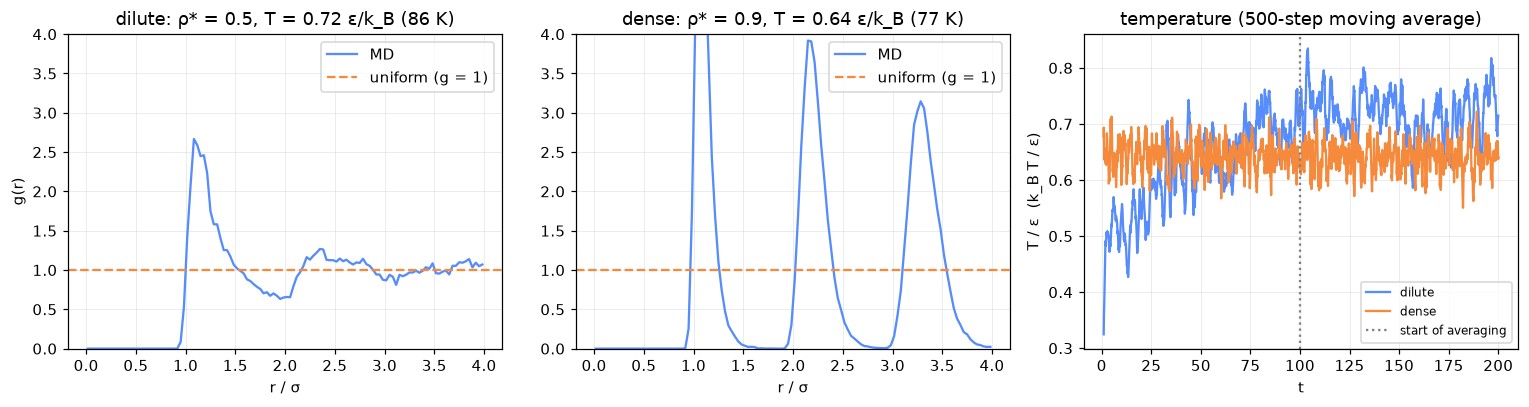

dilute: T = 86.0 K (first tenth of run: 60.4 K), g max = 2.67 at r = 1.08 sigma, mean g for r > 3 sigma = 1.00, energy error = 4.1e-05 eps per particle
dense: T = 76.7 K (first tenth of run: 77.3 K), g max = 6.05 at r = 1.08 sigma, mean g for r > 3 sigma = 1.14, energy error = 1.2e-04 eps per particle


In [47]:
# plot
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, c) in zip(axes[:2], chains.items()):
    ax.plot(c["r"] / SIGMA, c["g"], label="MD")
    ax.axhline(1.0, color="C1", ls="--", label="uniform (g = 1)")
    ax.set(xlabel="r / σ", ylim=(0, 4), title=f"{name}: ρ* = {c['rho']}, T = {c['T'] / EPS:.2f} ε/k_B ({c['T']:.0f} K)")
    ax.legend()
axes[0].set_ylabel("g(r)")
steps = np.arange(N_CHAIN_STEPS)
for name, c in chains.items():
    axes[2].plot(steps[SMOOTH - 1:] * DT, c["temperature_smooth"] / EPS, label=name)
axes[2].axvline(HALF * DT, color="grey", ls=":", label="start of averaging")
axes[2].set(xlabel="t", ylabel="T / ε  (k_B T / ε)", title=f"temperature ({SMOOTH}-step moving average)")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()
for name, c in chains.items():
    print(f"{name}: T = {c['T']:.1f} K (first tenth of run: {c['T_first_tenth']:.1f} K), "
          f"g max = {c['g_max']:.2f} at r = {c['g_max_r'] / SIGMA:.2f} sigma, mean g for r > 3 sigma = {c['g_mean_far']:.2f}, "
          f"energy error = {c['energy_error_per_particle']:.1e} eps per particle")

> **Expectation met?** For far distance in the dilute case, we start to see uniform distribution. this is reasonable as the attraction here is weak and we almost find an ideal gas. For denser arrangements we see sharp peaks in the respective minima which appear periodically in the radial distrbution function jsut as expected.
> The temeprature shift is also plausible as potential energy is shifted to kinetic energy as the initial velocity was set to 0.

# Summary

- All tests pass, and autodiff forces match the analytic ones to rounding precision.
- A bound pair oscillates around r_min = 2^(1/6) σ only for small offsets; its average position moves outward as the offset grows.
- Its distances are not uniform: the pair lingers at the turning points.
- Small oscillations follow the harmonic period, and the integrator is second order.
- In the chain, g(r) = 1 holds only at long distance in the dilute case, periodic density peaks correspond to the local energ minima for close and dense settings